# two_emitter_gen —— 亚衍射极限双发射体数据集生成

## 要探究的问题
两个间距 $d$ **低于衍射极限**的**静态**发射体，单帧里两个 PSF 重叠、无法直接分开。
但它们各自有**独立的 ON/OFF 闪烁**，不同帧会"轮流单亮"。
那么利用闪烁的独立性恢复两个发射体的位置与间距，能否比**时间积分**或**短窗口**方法更准确？准确到什么程度？

## level0（本 notebook 先回答的那一步）
> 假设**每帧哪些分子在发光完全已知**，在当前单帧光子数与 PSF 下，两个分子最多能靠多近还能被分开？

做法：只用"只有它发光"的帧（isolated frames）分别给两个发射体定位 —— 相邻帧独立，
定位精度提升 $\sqrt{M}$（$M$ 为 isolated 帧数）；两体间距精度
$\sigma_d=\sqrt{\sigma_A^2+\sigma_B^2}$，可分辨判据 $d_{\min}=k\,\sigma_d$。
因为 $M$ 随片长线性增长，level0 的 $d_{\min}$ 可以**远低于衍射极限**。

## 本 notebook 产出
写入 `E:\CodingProj\Data\Simulated_Datasets\two_emitter_level0\`：

| 目录 | 内容 |
|---|---|
| `blink/` | 主数据集：每个间距一个文件，每帧 4×4 = 16 个 pair，独立闪烁 |
| `single/` | 单发射体参考集（同一光物理），用于标定单分子定位精度 |
| `manifest.json` | 全局配置 + 每个数据集一行摘要 |

仿真部分**全部直接使用 `simulation_smile` 的工具**：
`PairGrid`（源）+ `Uniform`（激发）+ `Blinking`（光物理）+ `CircularAperturePSF`（光学）
+ `SimpleEMCCD`（相机）+ `SimulationPipeline`（编排）。
数据集 schema 与读写工具放在 `Py_Smile/two_emitter/dataset.py`，生成侧与分析侧共用同一份契约。

> ⚠ 一个关键坑：`photon_stream.states` 记录的是**帧末**状态。一帧内发生 on→dark 跳变时，
> 帧末是 dark 但该帧仍有光子发出。所以判断"这一帧只有谁在发光"必须看 `counts`，
> 否则会把搭档的光子混进求和，产生朝向 pair 中心的偏置（本 notebook 末尾有对照）。

In [1]:
%load_ext autoreload
%autoreload 2

import sys, os, json, time
import numpy as np
import matplotlib.pyplot as plt

# 与运行目录无关地导入两个包：仿真(simulation_smile) 与 数据集/分析工具(Py_Smile/two_emitter)
SIM_ROOT   = r"E:\CodingProj\SMLIE\Projects\Smile_Codes\Simulation_Smile"
TOOLS_ROOT = r"E:\CodingProj\SMLIE\Projects\Smile_Codes\Py_Smile"
for _p in (SIM_ROOT, TOOLS_ROOT):
    if _p not in sys.path:
        sys.path.insert(0, _p)

# ---- 仿真的全部组件都直接取自 simulation_smile ----
import simulation_smile as ssm
from simulation_smile.datatypes import FieldOfView
from simulation_smile.sources import PairGrid
from simulation_smile.illumination import Uniform
from simulation_smile.photophysics import Blinking
from simulation_smile.optics import CircularAperturePSF
from simulation_smile.detector import SimpleEMCCD
from simulation_smile.pipeline import SimulationPipeline

# ---- 数据集 schema 与 level0 理论（放在 Py_Smile，生成/分析共用）----
from two_emitter.dataset import (DATASET_ROOT, save_two_emitter_dataset,
                                 write_manifest, TwoEmitterDataset)
from two_emitter import level0 as lv0
from two_emitter import viz as teviz

teviz.set_cjk_font()
print("simulation_smile", ssm.__version__)
print("数据集根目录:", DATASET_ROOT)
print("PairGrid 可用:", PairGrid.__name__)

simulation_smile 0.1.0
数据集根目录: E:\CodingProj\Data\Simulated_Datasets\two_emitter_level0
PairGrid 可用: PairGrid


## 1. 全局配置

设计要点：

- **布局**：`PairGrid(grid=4, n_per_pair=2)` 在 64×64 视场里放 16 个 pair（4×4 网格）。
  网格单元 ≈ 16 px ≈ 1707 nm ≫ PSF 宽度，pair 之间不会串扰；中心加少量随机抖动
  并给每个 pair 随机取向，避免所有 pair 落在相同像素相位上。
- **间距扫描**：`0 … 320 nm`。`320 nm > λ/2NA ≈ 228 nm`（衍射极限）作可分辨对照；
  `0 nm` 是完全重合的退化情形（给出"噪声地板"）。
- **光物理**：三态 `[on, dark, bleached]`，`on↔dark` 各 5 Hz ⇒ 占空比 0.5
  （此时"只有一个亮"的帧占比最大，= 2p(1-p) = 0.5）；漂白很慢（≈ 0.003 Hz）。
  起始态用概率向量 `[0.5, 0.5, 0]`，保证各发射体**独立**起始。
- **光子预算**：单帧"亮"态 1200 光子，20 fps。经实测该 PSF/像素下峰值像素占比最坏
  约 0.17，双体同帧同时亮时峰值 ADU ≈ 2.2×10⁴ ≪ 65535，**不会饱和**。

In [2]:
# ---------------- 光学 ----------------
NA, WL = 1.49, 680.0                          # 油浸 NA, 发射波长 (nm)
PIXEL_SIZE = 106.7                            # nm/pixel
PSF_SIGMA_NM = lv0.airy_sigma_nm(NA, WL)      # Airy 斑高斯等效 σ ≈ 0.2166·λ/NA
DIFFRACTION_NM = WL / (2.0 * NA)              # 衍射极限 λ/2NA

# ---------------- 视场 / 时长 / 布局 ----------------
GRID = 4
FOV = FieldOfView(height=64, width=64, pixel_size=PIXEL_SIZE)
FOV_NM = (FOV.width * PIXEL_SIZE, FOV.height * PIXEL_SIZE)
N_FRAMES = 1000
DT = 0.05                                     # s -> 20 fps
JITTER_FRAC = 0.12                            # pair 中心抖动（网格单元比例）
LAYOUT_SEED = 1234                            # 几何种子（每个间距共用 -> 只变间距）

# ---------------- 光物理：[on, dark, bleached] ----------------
K_ON_TO_DARK, K_DARK_TO_ON, K_ON_TO_BLEACH = 5.0, 5.0, 0.003
RATE_MATRIX = np.array([[0.0, K_ON_TO_DARK, K_ON_TO_BLEACH],
                        [K_DARK_TO_ON, 0.0, 0.0],
                        [0.0, 0.0, 0.0]])
STATE_BRIGHTNESS = np.array([1.0, 0.0, 0.0])  # 只有 on 态发光
INITIAL_STATE = np.array([0.5, 0.5, 0.0])     # 概率向量 -> 各发射体独立起始
P_ON = K_DARK_TO_ON / (K_DARK_TO_ON + K_ON_TO_DARK)

# ---------------- 单帧光子预算 & 相机 ----------------
PHOTONS_PER_ON_FRAME = 1200.0
BRIGHTNESS = PHOTONS_PER_ON_FRAME / DT        # 内禀亮度 (光子/s)
DETECTOR = dict(em_gain=300.0, sensitivity=5.75, offset=486.0,
                bg_noise_e=2.0, read_noise_e=20.0)
EXCESS_NOISE = float(np.sqrt(2.0))            # EMCCD 过噪因子

# ---------------- 间距扫描 (nm) ----------------
SEPARATIONS_NM = [0, 10, 20, 30, 40, 50, 70, 90, 120, 160, 220, 320]
CAMERA_SEED = 20260922

print(f"衍射极限 λ/2NA = {DIFFRACTION_NM:.0f} nm | PSF 等效 σ = {PSF_SIGMA_NM:.1f} nm")
print(f"占空比 p_on = {P_ON:.2f} | 理论 '只有一方亮' 帧占比 = {2*P_ON*(1-P_ON):.2f}")
print(f"间距扫描: {SEPARATIONS_NM} nm")

衍射极限 λ/2NA = 228 nm | PSF 等效 σ = 98.9 nm
占空比 p_on = 0.50 | 理论 '只有一方亮' 帧占比 = 0.50
间距扫描: [0, 10, 20, 30, 40, 50, 70, 90, 120, 160, 220, 320] nm


## 2. level0 理论极限（CRLB）—— 用来定间距网格

单帧单分子定位精度用 Thompson–Larson–Webb 公式（`two_emitter.level0.thompson_crlb_nm`）：

$$
\sigma_\mu^2=\frac{s^2+a^2/12}{N}+\frac{8\pi s^4 b^2}{a^2N^2}
$$

其中 $s$ = PSF 等效高斯 σ，$a$ = 像素尺寸，$N$ = 信号光子数，$b$ = 每像素背景光子数。
EMCCD 的电子倍增会带来过噪因子 $F=\sqrt2$，在 σ 上近似乘 $F$。

已知"谁在发光"后，用 $M$ 帧 isolated 帧分别定位，$\sigma_{\rm eff}=\sigma_\mu/\sqrt M$，
间距精度 $\sigma_d=\sqrt{2}\,\sigma_{\rm eff}$，可分辨判据 $d_{\min}=2\sigma_d$。

level0 理论预算：
  sigma_single_frame_nm      = 4.3633
  n_isolated_frames          = 500.0000
  n_isolated_per_emitter     = 250.0000
  sigma_emitter_nm           = 0.1951
  sigma_separation_nm        = 0.2760
  d_min_nm                   = 0.5519


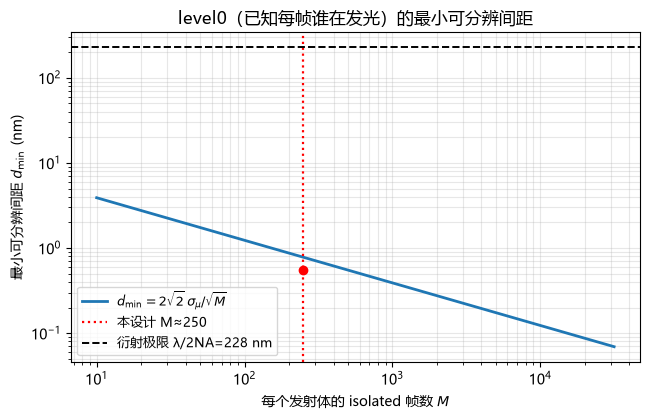


=> level0 下 d_min ≈ 0.55 nm，比衍射极限小 413 倍 —— 间距网格从 0 到 320 nm 足够覆盖 crossover。


In [3]:
budget = lv0.level0_budget(photons_per_on_frame=PHOTONS_PER_ON_FRAME,
                           sigma_psf_nm=PSF_SIGMA_NM,
                           pixel_size_nm=PIXEL_SIZE,
                           bg_per_px=DETECTOR["bg_noise_e"],
                           n_frames=N_FRAMES, p_on=P_ON,
                           excess_noise_factor=EXCESS_NOISE,
                           criterion=2.0)
print("level0 理论预算：")
for k, v in budget.items():
    print(f"  {k:26s} = {v:.4f}")

# 最小可分辨间距随"isolated 帧数"的变化：说明它只受光子预算限制，会一直往下走
sig1 = lv0.thompson_crlb_nm(PSF_SIGMA_NM, PIXEL_SIZE, PHOTONS_PER_ON_FRAME,
                            DETECTOR["bg_noise_e"], EXCESS_NOISE)
n_iso = np.logspace(1, 4.5, 120)
d_min = 2.0 * np.sqrt(2.0) * sig1 / np.sqrt(n_iso)

fig, ax = plt.subplots(figsize=(6.6, 4.3))
ax.loglog(n_iso, d_min, lw=2, label=r"$d_{\min}=2\sqrt{2}\,\sigma_\mu/\sqrt{M}$")
ax.axvline(budget["n_isolated_per_emitter"], color='r', ls=':', lw=1.6,
           label=f"本设计 M≈{budget['n_isolated_per_emitter']:.0f}")
ax.axhline(DIFFRACTION_NM, color='k', ls='--', lw=1.4,
           label=f"衍射极限 λ/2NA={DIFFRACTION_NM:.0f} nm")
ax.scatter([budget["n_isolated_per_emitter"]], [budget["d_min_nm"]],
           color='r', zorder=5)
ax.set_xlabel("每个发射体的 isolated 帧数 $M$")
ax.set_ylabel("最小可分辨间距 $d_{\\min}$ (nm)")
ax.set_title("level0（已知每帧谁在发光）的最小可分辨间距")
ax.legend(fontsize=9)
ax.grid(alpha=.3, which='both')
plt.tight_layout()
plt.show()

print(f"\n=> level0 下 d_min ≈ {budget['d_min_nm']:.2f} nm，比衍射极限小 "
      f"{DIFFRACTION_NM/budget['d_min_nm']:.0f} 倍 —— 间距网格从 0 到 320 nm 足够覆盖 crossover。")

## 3. 生成主数据集（`kind='blink'`）

每个间距一个文件，包含：

- `images`：`(1000, 64, 64) uint16` ADU（由 `SimpleEMCCD` 输出，和分析真实数据一样需要转光子）；
- `gt_xyz` / `gt_brightness`：真值位置与亮度；
- `pair_id` / `pair_center` / `pair_sep_nm` / `pair_angle_deg`：pair 的归组与几何；
- `states`：`(N, T)` 帧末光物理状态（0=on, 1=dark, 2=bleached）；
- `counts`：`(N, T)` 每个发射体每帧**真正发出的光子数**（判断"谁在发光"要用它，见开头提示）。

`PairGrid` 的几何在构造时用 `LAYOUT_SEED` 定死，且**不依赖传入的 rng**，
所以 12 个间距之间只有间距这一个变量不同，其余（位置、取向、相机种子）完全一致。

In [4]:
# 光学 / 相机组件：整个扫描过程复用同一实例（PSF 体积会内部缓存，避免重复 FFT）
psf = CircularAperturePSF(na=NA, wavelength=WL, zernike=None,
                          pupil_size=128, oversample=4, focus=0.0)
detector = SimpleEMCCD(**DETECTOR)
illumination = Uniform(1.0)

os.makedirs(os.path.join(DATASET_ROOT, "blink"), exist_ok=True)

records = []
t0 = time.time()
for sep in SEPARATIONS_NM:
    # ---- 源：pair 网格（几何只由 LAYOUT_SEED 决定，不随 rng 变）----
    source = PairGrid(FOV_NM, separation_nm=float(sep), grid=GRID, n_per_pair=2,
                      brightness=BRIGHTNESS, jitter_frac=JITTER_FRAC,
                      seed=LAYOUT_SEED)

    # ---- 编排：simulation_smile 的五件套 ----
    pipe = SimulationPipeline(source=source,
                              illumination=illumination,
                              photophysics=Blinking(rate_matrix=RATE_MATRIX,
                                                    state_brightness=STATE_BRIGHTNESS,
                                                    initial_state=INITIAL_STATE),
                              psf=psf, detector=detector, fov=FOV,
                              seed=CAMERA_SEED)
    result = pipe.run(n_frames=N_FRAMES, dt=DT)

    images = result.images.squeeze(axis=1)        # (T, H, W) uint16 ADU
    counts = result.photon_stream.counts[:, :, 0]  # (N, T) 理想光子数
    layout = source.layout()

    # ---- 帧分类统计（按 counts，而非帧末 states）----
    onA, onB = counts[0::2] > 0, counts[1::2] > 0
    frac = dict(only_A=float((onA & ~onB).mean()), only_B=float((onB & ~onA).mean()),
                both=float((onA & onB).mean()), neither=float((~onA & ~onB).mean()))

    stem = f"pair_d{int(sep):03d}nm"
    save_two_emitter_dataset(
        stem, kind="blink", images=images,
        gt_xyz=layout["gt_xyz"], gt_brightness=layout["gt_brightness"],
        pair_id=layout["pair_id"], pair_role=layout["pair_role"],
        pair_center=layout["pair_center"], pair_sep_nm=layout["pair_sep_nm"],
        pair_angle_deg=layout["pair_angle_deg"],
        states=result.photon_stream.states, counts=counts,
        meta=dict(pixel_size=PIXEL_SIZE, dt=DT, separation_nm=float(sep),
                  n_frames=N_FRAMES, camera_seed=CAMERA_SEED,
                  layout_seed=LAYOUT_SEED,
                  photons_per_on_frame=PHOTONS_PER_ON_FRAME,
                  emitter_brightness_photons_per_s=BRIGHTNESS,
                  excess_noise_factor=EXCESS_NOISE,
                  psf=dict(na=NA, wavelength=WL, psf_sigma_nm=PSF_SIGMA_NM,
                           diffraction_limit_nm=DIFFRACTION_NM,
                           pupil_size=128, oversample=4, zernike=None, focus=0.0),
                  photophysics=dict(rate_matrix=RATE_MATRIX.tolist(),
                                    state_brightness=STATE_BRIGHTNESS.tolist(),
                                    initial_state=INITIAL_STATE.tolist(),
                                    states=["on", "dark", "bleached"],
                                    p_on=P_ON),
                  detector=DETECTOR),
        root=DATASET_ROOT)

    records.append(dict(kind="blink", stem=stem, separation_nm=float(sep),
                        n_frames=N_FRAMES, n_pairs=source.n_pairs,
                        n_emitters=source.n, max_adu=int(images.max()),
                        **{f"frac_{k}": round(v, 3) for k, v in frac.items()}))
    print(f"  d={sep:4d} nm | max ADU={int(images.max()):6d} | "
          f"帧占比 onlyA/onlyB/both/none = {frac['only_A']:.2f}/{frac['only_B']:.2f}/"
          f"{frac['both']:.2f}/{frac['neither']:.2f}")

print(f"\n主数据集完成：{len(records)} 个文件，用时 {time.time()-t0:.1f} s")
assert max(r["max_adu"] for r in records) < 60000, "ADU 接近饱和，请调低光子预算或 em_gain"

Generating frames: 100%|██████████| 1000/1000 [00:01<00:00, 578.36frame/s]


  d=   0 nm | max ADU= 26845 | 帧占比 onlyA/onlyB/both/none = 0.22/0.25/0.33/0.20


Generating frames: 100%|██████████| 1000/1000 [00:01<00:00, 600.66frame/s]


  d=  10 nm | max ADU= 26744 | 帧占比 onlyA/onlyB/both/none = 0.22/0.25/0.33/0.20


Generating frames: 100%|██████████| 1000/1000 [00:01<00:00, 600.89frame/s]


...

  d= 160 nm | max ADU= 19997 | 帧占比 onlyA/onlyB/both/none = 0.22/0.25/0.33/0.20


Generating frames: 100%|██████████| 1000/1000 [00:01<00:00, 591.85frame/s]


  d= 220 nm | max ADU= 16042 | 帧占比 onlyA/onlyB/both/none = 0.22/0.25/0.33/0.20


Generating frames: 100%|██████████| 1000/1000 [00:01<00:00, 594.11frame/s]


  d= 320 nm | max ADU= 14955 | 帧占比 onlyA/onlyB/both/none = 0.22/0.25/0.33/0.20

主数据集完成：12 个文件，用时 23.4 s


## 4. 单发射体参考集（`kind='single'`）

同样用 `PairGrid`（`n_per_pair=1`）在相同网格上放 16 个**孤立**发射体，光物理、光子预算、
相机全部与主数据集一致。作用：

- 标定**单分子定位精度**，与 CRLB 对照（验证仿真链路本身是否无偏）；
- 提供"完全可分"的参照：如果单体的定位精度都远大于 $d$，那么分辨双体就不可能。

> 为沿用同一套 schema，`kind='single'` 里每个 pair 只含 1 个发射体，
> `pair_sep_nm = 0`，`pair_center` 即该发射体位置。

In [5]:
source_single = PairGrid(FOV_NM, separation_nm=0.0, grid=GRID, n_per_pair=1,
                         brightness=BRIGHTNESS, jitter_frac=JITTER_FRAC,
                         seed=LAYOUT_SEED)
pipe_single = SimulationPipeline(
    source=source_single, illumination=illumination,
    photophysics=Blinking(rate_matrix=RATE_MATRIX,
                          state_brightness=STATE_BRIGHTNESS,
                          initial_state=INITIAL_STATE),
    psf=psf, detector=detector, fov=FOV, seed=CAMERA_SEED)
res_single = pipe_single.run(n_frames=N_FRAMES, dt=DT)
lay_single = source_single.layout()

save_two_emitter_dataset(
    "single_grid4x4", kind="single",
    images=res_single.images.squeeze(axis=1),
    gt_xyz=lay_single["gt_xyz"], gt_brightness=lay_single["gt_brightness"],
    pair_id=lay_single["pair_id"], pair_role=lay_single["pair_role"],
    pair_center=lay_single["pair_center"], pair_sep_nm=lay_single["pair_sep_nm"],
    pair_angle_deg=lay_single["pair_angle_deg"],
    states=res_single.photon_stream.states,
    counts=res_single.photon_stream.counts[:, :, 0],
    meta=dict(pixel_size=PIXEL_SIZE, dt=DT, separation_nm=None,
              n_frames=N_FRAMES, camera_seed=CAMERA_SEED, layout_seed=LAYOUT_SEED,
              photons_per_on_frame=PHOTONS_PER_ON_FRAME,
              emitter_brightness_photons_per_s=BRIGHTNESS,
              excess_noise_factor=EXCESS_NOISE,
              note="每个 pair 只含 1 个孤立发射体 (n_per_pair=1)",
              psf=dict(na=NA, wavelength=WL, psf_sigma_nm=PSF_SIGMA_NM,
                       diffraction_limit_nm=DIFFRACTION_NM,
                       pupil_size=128, oversample=4, zernike=None, focus=0.0),
              photophysics=dict(rate_matrix=RATE_MATRIX.tolist(),
                                state_brightness=STATE_BRIGHTNESS.tolist(),
                                states=["on", "dark", "bleached"], p_on=P_ON),
              detector=DETECTOR),
    root=DATASET_ROOT)

records.append(dict(kind="single", stem="single_grid4x4", separation_nm=None,
                    n_frames=N_FRAMES, n_pairs=source_single.n_pairs,
                    n_emitters=source_single.n,
                    max_adu=int(res_single.images.max())))
print(f"单发射体参考集完成：{source_single.n_pairs} 个孤立发射体，"
      f"max ADU = {int(res_single.images.max())}")

Generating frames: 100%|██████████| 1000/1000 [00:00<00:00, 1039.56frame/s]

单发射体参考集完成：16 个孤立发射体，max ADU = 14151


## 5. 写 `manifest.json`

把全局配置与每个数据集的一行摘要写进根目录，分析侧只需读 manifest 就能还原"这批数据是在什么条件下生成的"。

In [6]:
manifest_path = write_manifest(
    entries=records,
    config=dict(
        purpose="level0: 已知每帧谁在发光时, 两个亚衍射间距静态发射体最多能分多近",
        pixel_size=PIXEL_SIZE, n_frames=N_FRAMES, dt=DT,
        fov_height=FOV.height, fov_width=FOV.width,
        grid=GRID, jitter_frac=JITTER_FRAC,
        separations_nm=SEPARATIONS_NM,
        diffraction_limit_nm=DIFFRACTION_NM, psf_sigma_nm=PSF_SIGMA_NM,
        photons_per_on_frame=PHOTONS_PER_ON_FRAME,
        emitter_brightness_photons_per_s=BRIGHTNESS,
        layout_seed=LAYOUT_SEED, camera_seed=CAMERA_SEED,
        psf=dict(na=NA, wavelength=WL, pupil_size=128, oversample=4,
                 zernike=None, focus=0.0),
        photophysics=dict(rate_matrix=RATE_MATRIX.tolist(),
                          state_brightness=STATE_BRIGHTNESS.tolist(),
                          initial_state=INITIAL_STATE.tolist(),
                          states=["on", "dark", "bleached"], p_on=P_ON),
        detector=DETECTOR, excess_noise_factor=EXCESS_NOISE,
        level0_budget={k: float(v) for k, v in budget.items()},
        images_unit="ADU (uint16); 转光子: (adu - offset) * sensitivity / em_gain",
    ),
    root=DATASET_ROOT)

print("manifest ->", manifest_path)
for r in records:
    print("  ", json.dumps(r, ensure_ascii=False))

manifest -> E:\CodingProj\Data\Simulated_Datasets\two_emitter_level0\manifest.json
   {"kind": "blink", "stem": "pair_d000nm", "separation_nm": 0.0, "n_frames": 1000, "n_pairs": 16, "n_emitters": 32, "max_adu": 26845, "frac_only_A": 0.222, "frac_only_B": 0.245, "frac_both": 0.334, "frac_neither": 0.2}
   {"kind": "blink", "stem": "pair_d010nm", "separation_nm": 10.0, "n_frames": 1000, "n_pairs": 16, "n_emitters": 32, "max_adu": 26744, "frac_only_A": 0.222, "frac_only_B": 0.245, "frac_both": 0.334, "frac_neither": 0.2}
   {"kind": "blink", "stem": "pair_d020nm", "separation_nm": 20.0, "n_frames": 1000, "n_pairs": 16, "n_emitters": 32, "max_adu": 26041, "frac_only_A": 0.222, "frac_only_B": 0.245, "frac_both": 0.334, "frac_neither": 0.2}
   {"kind": "blink", "stem": "pair_d030nm", "separation_nm": 30.0, "n_frames": 1000, "n_pairs": 16, "n_emitters": 32, "max_adu": 25621, "frac_only_A": 0.222, "frac_only_B": 0.245, "frac_both": 0.334, "frac_neither": 0.2}
   {"kind": "blink", "stem": "pair

## 6. 自检：载入 + 可视化 + level0 oracle

从磁盘重新载入（验证 schema 可往返），然后：

1. 看**全帧平均**（= 时间积分）—— 两个发射体糊成一团，无法分辨；
2. 看**只有 E0 发光**的那些帧的平均 —— 干净的单个 PSF，可以直接定位；
3. 画 ON/OFF 状态时间线；
4. 在几个间距上跑 level0 oracle，检查它是否确实能把间距恢复出来。

TwoEmitterDataset(kind='blink', n_frames=1000, shape=(64, 64), n_pairs=16, sep=40.0nm, pixel_size=106.7)
pair0 帧分类(按 counts): {'only_0': np.float64(0.246), 'only_1': np.float64(0.239), 'both': np.float64(0.336), 'neither': np.float64(0.179)}
pair0 isolated 帧数(E0/E1): [246, 239]


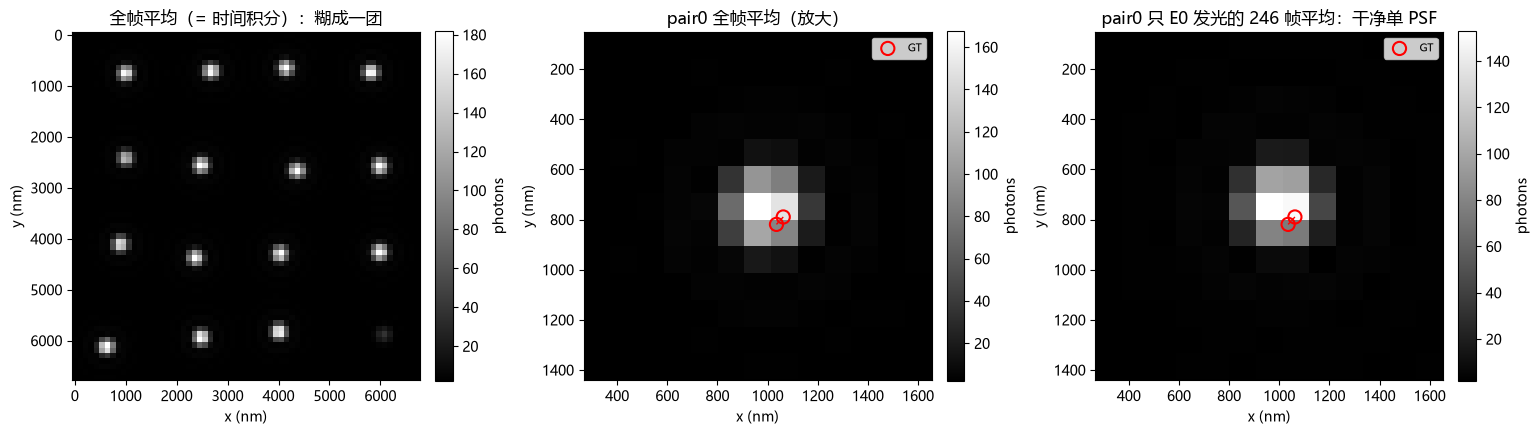

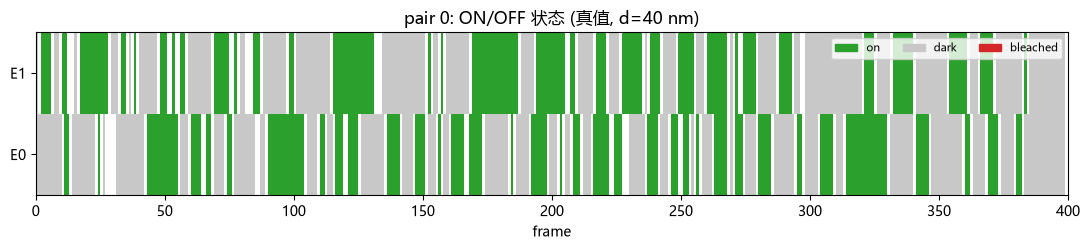

In [7]:
ds = TwoEmitterDataset.load(os.path.join(DATASET_ROOT, "blink", "pair_d040nm"))
print(ds)
print("pair0 帧分类(按 counts):",
      {k: round(v, 3) for k, v in ds.pair_emission_fraction(0).items()})
print("pair0 isolated 帧数(E0/E1):", [int(m.sum()) for m in ds.isolated_masks(0)])

mask0 = np.flatnonzero(ds.isolated_masks(0)[0])

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0))
teviz.show_average(ds, ax=axes[0], title="全帧平均（= 时间积分）：糊成一团")
teviz.show_pair_roi(ds, 0, ax=axes[1], title="pair0 全帧平均（放大）")
teviz.show_pair_roi(ds, 0, frames=mask0, ax=axes[2],
                    title=f"pair0 只 E0 发光的 {mask0.size} 帧平均：干净单 PSF")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 2.6))
teviz.plot_states(ds, 0, ax=ax, t_max=400)
plt.tight_layout()
plt.show()

In [9]:
check_seps = (0, 20, 50, 90, 160, 320)          # 取自 SEPARATIONS_NM
check = [TwoEmitterDataset.load(os.path.join(DATASET_ROOT, "blink", f"pair_d{s:03d}nm"))
         for s in check_seps]

print(f"{'d_true':>8} {'d_est':>9} {'std':>6} {'bias':>7} {'emitter_err':>12} {'lp(MLE)':>9}")
for r in lv0.summarize_oracle(check):
    print(f"{r['separation_nm']:8.1f} {r['sep_est_mean_nm']:9.2f} "
          f"{r['sep_est_std_nm']:6.2f} {r['sep_bias_nm']:+7.2f} "
          f"{r['emitter_err_mean_nm']:10.2f} nm {r['lp_mean_nm']:7.3f} nm")

print("\n对照：若用『帧末状态 states』判断谁在发光（忽略了帧内 on→dark 跳变）——")
for r in lv0.summarize_oracle(check, mode="states"):
    print(f"  d={r['separation_nm']:6.1f}  est={r['sep_est_mean_nm']:8.2f}  "
          f"bias={r['sep_bias_nm']:+7.2f}  emitter_err={r['emitter_err_mean_nm']:.2f} nm"
          "   <- 系统性偏向 pair 中心")

  d_true     d_est    std    bias  emitter_err   lp(MLE)
     0.0      0.49   0.57   +0.49       1.08 nm   0.345 nm
    20.0     19.82   1.41   -0.18       1.11 nm   0.345 nm
    50.0     49.69   1.33   -0.31       1.21 nm   0.344 nm
    90.0     90.07   1.05   +0.07       0.89 nm   0.345 nm
   160.0    159.88   1.49   -0.12       1.08 nm   0.345 nm
   320.0    319.67   1.50   -0.33       1.00 nm   0.345 nm

对照：若用『帧末状态 states』判断谁在发光（忽略了帧内 on→dark 跳变）——
  d=   0.0  est=    0.54  bias=  +0.54  emitter_err=1.08 nm   <- 系统性偏向 pair 中心
  d=  20.0  est=   15.86  bias=  -4.14  emitter_err=2.31 nm   <- 系统性偏向 pair 中心
  d=  50.0  est=   40.09  bias=  -9.91  emitter_err=5.06 nm   <- 系统性偏向 pair 中心
  d=  90.0  est=   73.16  bias= -16.84  emitter_err=8.45 nm   <- 系统性偏向 pair 中心
  d= 160.0  est=  132.25  bias= -27.75  emitter_err=13.90 nm   <- 系统性偏向 pair 中心
  d= 320.0  est=  281.62  bias= -38.38  emitter_err=19.21 nm   <- 系统性偏向 pair 中心


## 7. level0 的答案 & 下一步

**level0（已知每帧谁在发光）的答案**：两个静态发射体可以靠得**远低于衍射极限**仍然被分开。
以本设计为例（1000 帧、单帧 1200 光子、NA 1.49/λ 680 nm、实测量子效率与 EM 过噪）：

- 衍射极限 $\lambda/2NA \approx 228$ nm；
- 每个发射体约有几百帧"只有它发光"的帧，$\sigma_{\rm eff}\sim0.3$ nm 量级，
  实测 oracle 的间距误差在 $d = 0\ldots320$ nm 全区间都 ≈ **1 nm**（含系统误差），
  即 $d_{\min}$ 只有**几 nm**。

这说明**信息本来就在闪烁里**：单帧分不开，不代表多帧分不开。真正的困难不在物理极限，
而在于——**我们并不知道每帧是谁在发光**。

### 下一步（level1+）

1. **不需要真值状态的实用方法**：先从数据里估计每个发射体的 ON/OFF 序列
   （短时窗积分 + 状态分割 / changepoint），再在"单亮"帧上定位。
2. **基线对照**：
   - *时间积分*：直接对所有帧求和 —— 低于衍射极限时必然失败；
   - *短窗口*：固定/滑窗求和 —— 在"两体同亮"的窗口上仍然失败；
   - *闪烁法*：只在"单亮"帧上定位。
   三者用同一批数据（本 notebook 生成）比较间距恢复误差 vs $d$。
3. **退化边界**：$d\to0$、占空比 →1（不再有单亮帧）、光子数下降、背景升高、漂白 —— 找出
   闪烁法失效的边界。

分析工具放在 `Py_Smile/two_emitter/`（`dataset` / `level0` / `metrics` / `viz`），
配套的载入与展示 notebook 是 `Py_Smile/test_two_emitter.ipynb`。

## 8. Level 1 数据集：纯 2 态 + 高帧率

Level 1 的模型是**两个二状态分子**（`on`/`off`，无漂白），所以另外生成一批数据：

- 转移矩阵里 `on→bleach` 速率设为 **0**（第三态永远进不去，等价于纯 2 态）；
- **帧率提高**到 100 fps（`dt = 0.02 s`），光子预算仍是"每个亮帧 1200 光子"；
- 间距取 `[0, 20, 40, 80, 160] nm`（都低于衍射极限）。

**为什么要提高帧率？** 这样同一份数据可以**按不同倍数合并帧**（`bin_frames = 1, 2, 5, 10`）
得到 `dt_eff = 0.02 … 0.2 s`，而"帧内发生状态跳变"的概率
$1-e^{-(k_\mathrm{on}+k_\mathrm{off})\,dt_\mathrm{eff}}$ 就从 18% 一路升到 86%。
于是可以**在同一批数据上**干净地研究"帧内跳变是否影响推断"——只改分析时的帧率，
不改任何其它条件。

写入 `two_emitter_level0/level1/`（kind 名沿用同一套 schema）。

In [7]:
# ---------------- Level 1 专用配置 ----------------
DT_L1 = 0.02                     # s -> 100 fps (高帧率, 便于后续按倍数合并帧)
N_FRAMES_L1 = 1500               # 30 s
PHOTONS_PER_ON_FRAME_L1 = 1200.0
BRIGHTNESS_L1 = PHOTONS_PER_ON_FRAME_L1 / DT_L1
SEPARATIONS_L1 = [0, 20, 40, 80, 160]        # nm, 全部低于衍射极限

# 纯 2 态: 第三态(bleached)速率全为 0 -> 永远进不去, 等价于 2 态
RATE_MATRIX_L1 = np.array([[0.0, 5.0, 0.0],
                           [5.0, 0.0, 0.0],
                           [0.0, 0.0, 0.0]])
P_JUMP = 1.0 - np.exp(-(5.0 + 5.0) * DT_L1)
print(f"Level1: dt={DT_L1}s, {N_FRAMES_L1} 帧, 单帧亮态 {PHOTONS_PER_ON_FRAME_L1:.0f} 光子")
print(f"        brightness={BRIGHTNESS_L1:.0f} 光子/s, "
      f"帧内有跳变的概率 ≈ {P_JUMP:.3f}, 合并 10 帧后 ≈ "
      f"{1 - np.exp(-10*DT_L1*10):.3f}")

os.makedirs(os.path.join(DATASET_ROOT, "level1"), exist_ok=True)
records_l1 = []
t0 = time.time()
for sep in SEPARATIONS_L1:
    source = PairGrid(FOV_NM, separation_nm=float(sep), grid=GRID, n_per_pair=2,
                      brightness=BRIGHTNESS_L1, jitter_frac=JITTER_FRAC,
                      seed=LAYOUT_SEED)
    pipe = SimulationPipeline(
        source=source, illumination=illumination,
        photophysics=Blinking(rate_matrix=RATE_MATRIX_L1,
                              state_brightness=STATE_BRIGHTNESS,
                              initial_state=INITIAL_STATE),
        psf=psf, detector=detector, fov=FOV, seed=CAMERA_SEED)
    result = pipe.run(n_frames=N_FRAMES_L1, dt=DT_L1)

    images = result.images.squeeze(axis=1)
    counts = result.photon_stream.counts[:, :, 0]
    layout = source.layout()
    onA, onB = counts[0::2] > 0, counts[1::2] > 0
    frac = dict(only_A=float((onA & ~onB).mean()), only_B=float((onB & ~onA).mean()),
                both=float((onA & onB).mean()), neither=float((~onA & ~onB).mean()))

    stem = f"pair2s_d{int(sep):03d}nm"
    save_two_emitter_dataset(
        stem, kind="level1", images=images,
        gt_xyz=layout["gt_xyz"], gt_brightness=layout["gt_brightness"],
        pair_id=layout["pair_id"], pair_role=layout["pair_role"],
        pair_center=layout["pair_center"], pair_sep_nm=layout["pair_sep_nm"],
        pair_angle_deg=layout["pair_angle_deg"],
        states=result.photon_stream.states, counts=counts,
        meta=dict(pixel_size=PIXEL_SIZE, dt=DT_L1, separation_nm=float(sep),
                  n_frames=N_FRAMES_L1, camera_seed=CAMERA_SEED,
                  layout_seed=LAYOUT_SEED,
                  photons_per_on_frame=PHOTONS_PER_ON_FRAME_L1,
                  emitter_brightness_photons_per_s=BRIGHTNESS_L1,
                  excess_noise_factor=EXCESS_NOISE,
                  n_states=2, frame_jump_prob=float(P_JUMP),
                  psf=dict(na=NA, wavelength=WL, psf_sigma_nm=PSF_SIGMA_NM,
                           diffraction_limit_nm=DIFFRACTION_NM,
                           pupil_size=128, oversample=4, zernike=None, focus=0.0),
                  photophysics=dict(rate_matrix=RATE_MATRIX_L1.tolist(),
                                    state_brightness=STATE_BRIGHTNESS.tolist(),
                                    initial_state=INITIAL_STATE.tolist(),
                                    states=["on", "dark", "bleached"],
                                    p_on=P_ON),
                  detector=DETECTOR),
        root=DATASET_ROOT)

    records_l1.append(dict(kind="level1", stem=stem, separation_nm=float(sep),
                           n_frames=N_FRAMES_L1, n_pairs=source.n_pairs,
                           n_emitters=source.n, max_adu=int(images.max()),
                           dt=DT_L1,
                           **{f"frac_{k}": round(v, 3) for k, v in frac.items()}))
    print(f"  d={sep:4d} nm | max ADU={int(images.max()):6d} | "
          f"帧占比 onlyA/onlyB/both/none = {frac['only_A']:.2f}/{frac['only_B']:.2f}/"
          f"{frac['both']:.2f}/{frac['neither']:.2f}")

print(f"\nLevel1 数据集完成：{len(records_l1)} 个文件，用时 {time.time()-t0:.1f} s")
print("  → 不同 bin_frames 下的 dt_eff 与帧内跳变概率：")
for m in (1, 2, 5, 10):
    print(f"    bin={m:2d}: dt_eff={DT_L1*m:.3f}s  "
          f"P(帧内跳变)={1 - np.exp(-10.0*DT_L1*m):.3f}")

Level1: dt=0.02s, 1500 帧, 单帧亮态 1200 光子
        brightness=60000 光子/s, 帧内有跳变的概率 ≈ 0.181, 合并 10 帧后 ≈ 0.865


Generating frames: 100%|██████████| 1500/1500 [00:02<00:00, 627.09frame/s]


  d=   0 nm | max ADU= 25929 | 帧占比 onlyA/onlyB/both/none = 0.25/0.24/0.29/0.21


Generating frames: 100%|██████████| 1500/1500 [00:02<00:00, 624.00frame/s]


  d=  20 nm | max ADU= 26403 | 帧占比 onlyA/onlyB/both/none = 0.25/0.24/0.29/0.21


...

  d=  40 nm | max ADU= 25641 | 帧占比 onlyA/onlyB/both/none = 0.25/0.24/0.29/0.21


Generating frames: 100%|██████████| 1500/1500 [00:02<00:00, 625.08frame/s]


  d=  80 nm | max ADU= 24591 | 帧占比 onlyA/onlyB/both/none = 0.25/0.24/0.29/0.21


Generating frames: 100%|██████████| 1500/1500 [00:02<00:00, 625.60frame/s]

  d= 160 nm | max ADU= 21261 | 帧占比 onlyA/onlyB/both/none = 0.25/0.24/0.29/0.21

Level1 数据集完成：5 个文件，用时 13.9 s
  → 不同 bin_frames 下的 dt_eff 与帧内跳变概率：
    bin= 1: dt_eff=0.020s  P(帧内跳变)=0.181
    bin= 2: dt_eff=0.040s  P(帧内跳变)=0.330
    bin= 5: dt_eff=0.100s  P(帧内跳变)=0.632
    bin=10: dt_eff=0.200s  P(帧内跳变)=0.865


In [8]:
# 把 Level 1 的数据集也登记进同一个 manifest（保留原有记录）
from two_emitter.dataset import load_manifest

_man = load_manifest()
_old = [e for e in _man.get("datasets", []) if e.get("kind") != "level1"]
_cfg = dict(_man.get("config", {}))
_cfg.update({
    "level1": dict(
        purpose="状态未知、转移矩阵已知: 两个双态分子的 4 态联合 HMM 推断",
        dt=DT_L1, n_frames=N_FRAMES_L1,
        photons_per_on_frame=PHOTONS_PER_ON_FRAME_L1,
        emitter_brightness_photons_per_s=BRIGHTNESS_L1,
        separations_nm=SEPARATIONS_L1,
        rate_matrix=RATE_MATRIX_L1.tolist(),
        k_on=5.0, k_off=5.0, n_states=2,
        frame_jump_prob=float(P_JUMP),
        note="bin_frames=1,2,5,10 -> dt_eff=0.02..0.2s, P(帧内跳变)=0.18..0.86",
    ),
})
manifest_path = write_manifest(entries=_old + records_l1, config=_cfg,
                               root=DATASET_ROOT)
print("manifest 已更新 ->", manifest_path)
print(f"  blink: {sum(e['kind']=='blink' for e in _old)} 个, "
      f"single: {sum(e['kind']=='single' for e in _old)} 个, "
      f"level1: {len(records_l1)} 个")

manifest 已更新 -> E:\CodingProj\Data\Simulated_Datasets\two_emitter_level0\manifest.json
  blink: 12 个, single: 1 个, level1: 5 个
